# 시계열 정리

---

### 1. 시계열 데이터

#### 1-1. 정의

- **시계열 데이터**
: 시간 흐름에 따라 일정한 간격으로, 순서대로 관측, 기록한 데이터 (주가, 기온, 매출)
    - 표기: $t$ 시점, $Y_t$ t 시점 관측값, $T$ 마지막 관측 시점
    - 조건: 순서 자체가 정보 (섞으면 의미 사라짐), 관측 간격 (주기) 일정

- **단변량 vs 다변량**
    - 단변량: 변수 1개, 자기 과거로만 예측 
    - 다변량: 변수 여러 개, 다른 변수 영향까지 고려 

- **시계열 분석**
: 패턴을 찾아 미래 값을 예측 (Forecasting)
    - 가정: 과거 패턴이 미래에도 반복됨 → 새로운 사건, 먼 미래는 예측 어려움
    - 목적: 예측 자체보다 예측을 바탕으로 '미리' 결정 
    - 일반 회귀 X → 어제 값이 오늘 값에 영향 

#### 1-2. 특징

- **시간의존성**: 현재 값이 과거 값의 영향을 받음, 가까운 과거일수록 영향 큼 → 순서 섞으면 안 됨 (데이터 누수 주의)
- **계절성**: 일정 주기로 비슷한 패턴 반복 → 언제마다 반복되나?
- **추세**: 데이터가 장기적으로 증가 / 감소하는 방향성 → 어느 방향으로 가나?
    - 실제로는 둘이 동시에 나타남 

- **자기상관성** 
: 같은 변수의 현재와 과거가 얼마나 비슷하게 움직이는지
    - 범위 -1 ~ 1 (1: 비례, -1: 반비례, 0: 무관)
    - 시차 (Lag): 현 값을 몇 시점 전과 비교하는지 → 시차를 바꿔가며 계산하면 주기 발견 
    - 문제: 오차항 독립성 가정 위반 → 통계 결과 왜곡, 허위 상관, 예측 어려움 → 일반 회귀 불가
    - 해결: 시계열 전용 모델 (자기상관을 정보로 활용) or 전처리 (차분, 추세 제거)

#### 1-3. 분석 요인

- **추세 (T)**
: 장기적으로 증가하거나 감소하는 방향 → 주기 없음, 예측 가능성 높음
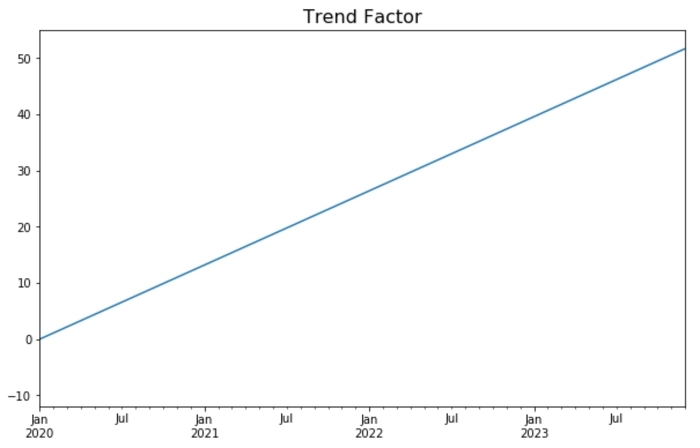
- **계절 (S)**
: 1년 이내의 정해진 주기로 반복되는 패턴 → 주기 고정, 예측 가능성 높음 
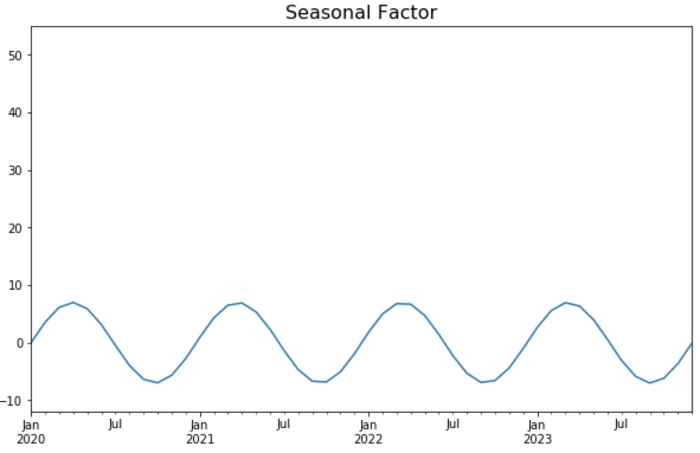
- **순환 (C)**
: 수년 단위의 불규칙한 주기로 오르내리는 변동 (대표적으로 경기 변동) → 예측 가능성 낮음 
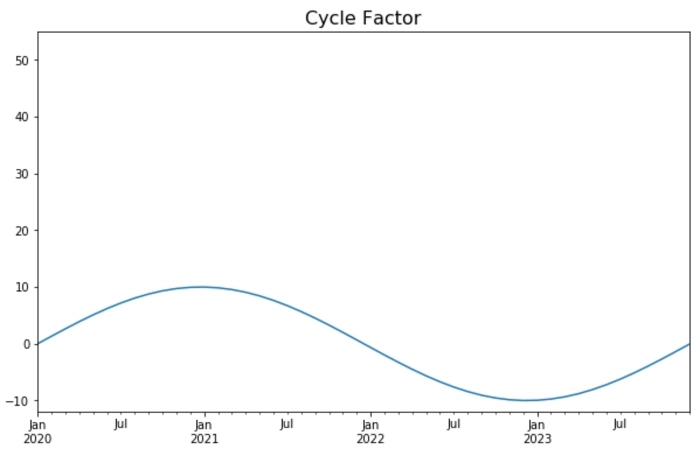
- **불규칙 (I)**
: 위 요인으로 설명되지 않는 나머지 (잔차, 노이즈) → 주기 없음, 예측 불가능
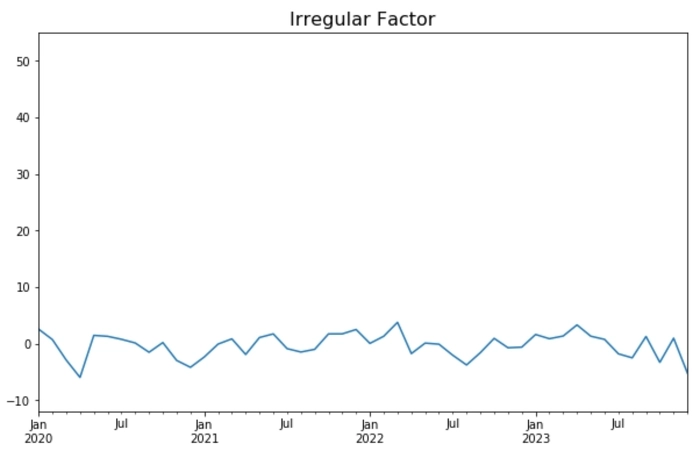
- 실제 시계열 = 4가지 요인이 섞인 결과 → 하나씩 떼어보는 게 요소 분해

---

### 2. 전처리

- 필요성: 결측치, 이상치, 노이즈 → 값 하나가 앞뒤와 이어져 있어 주변 분석까지 망가짐
- 순서: 데이터 확인 → 결측치 탐지, 처리 → 이상치 탐지, 처리 → 평활화 → 요소분해 → 정상성 판단, 확보

#### 2-1. 결측치 / 이상치

- **결측치 처리**
    - 행 삭제 → 관측 간격 깨짐 / 전체 평균 대치 → 시간 흐름 무시됨
    - 삭제: 결측이 매우 적고 맨 앞 or 뒤일 때만
    - 단순 대치: 평균, 중앙값, 최빈값으로 → 추세와 계절성 무시
    - **보간**: 앞뒤 값을 연결해 사이 값 추정 → 시계열에서 가장 많이 씀 
    - 이동평균 대치: 주변 구간 평균으로 → 구간 크기 정해야 함
    - 머신러닝 (KNN, 회귀): 정교하지만 복잡

- **이상치**
: 일반 패턴에서 크게 벗어난 값 → 시계열에선 '언제'가 중요 (추세, 계절성 고려)

- **탐지 방법**
    - IQR: Q1−1.5×IQR 미만, Q3+1.5×IQR 초과
        - 간단하고, 정규분포 가정 X 
        - 추세, 계절성 강하면 부적합 → 구간별 or 잔차에 적용
        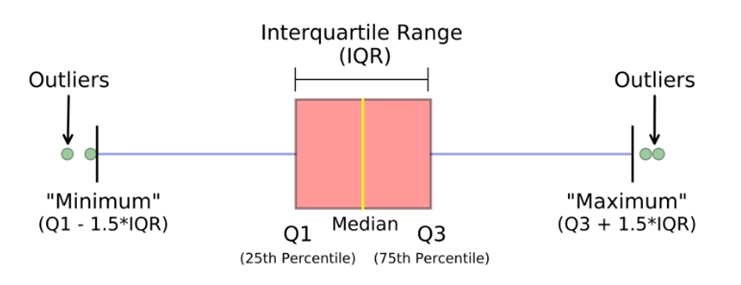
    - Z-score: |Z| > 3 
        - 간단하고, 정규분포 가정 o
        - 이상치가 평균, 표준편차 자체를 끌어올림 → Rolling Z-score로 적용
    - STL 분해: 추세, 계절 제거 후 잔차가 임곗값 넘으면 이상치 
        - 진짜 이상한 값만 잡음 
        - 계산 비용 큼

- **탐지 모델**
    - CART: 다음 시점 예측, 예측 오차 큰 곳 → 이상치
        - 비선형, 다변량 적용 가능 
        - 과적합 쉬움
        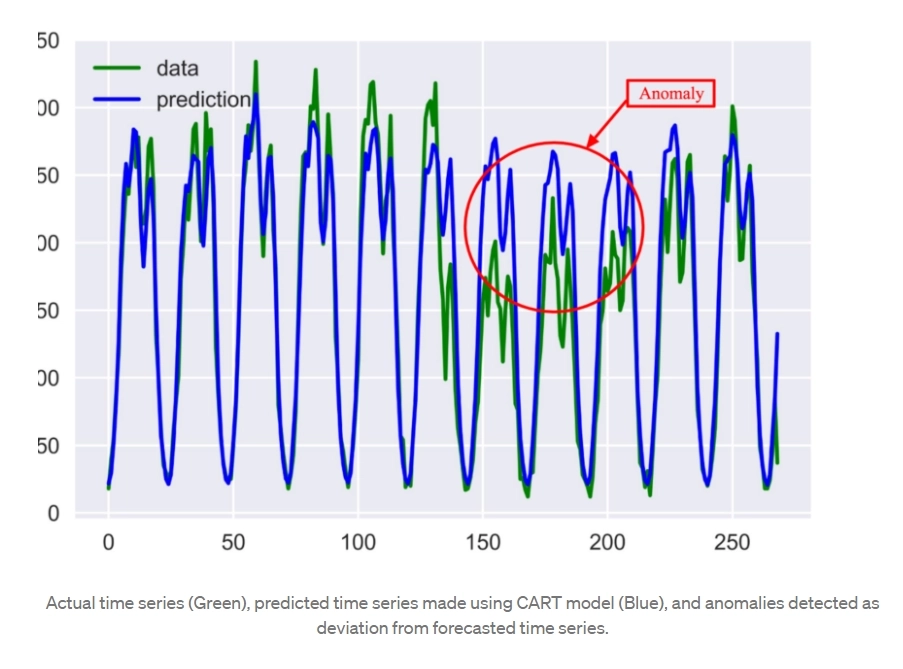
    - 클러스터링 (K-means, DBSCAN): 어느 군집에도 안 속하는 데이터 → 이상치
        - 비지도에도 사용 가능, 집단 이상치도 탐지 가능
        - 하이퍼파라미터에 민감, 순서 정보 반영 X
    - 오토인코더: 정상 데이터로 압축, 복원해 학습, 복원 오차 큰 곳 → 이상치
        - LSTM AE면 시간 의존성까지 학습 가능 
        - 다변량까지 적용 가능
        - 데이터, 계산량 많음, 해석 어려움
        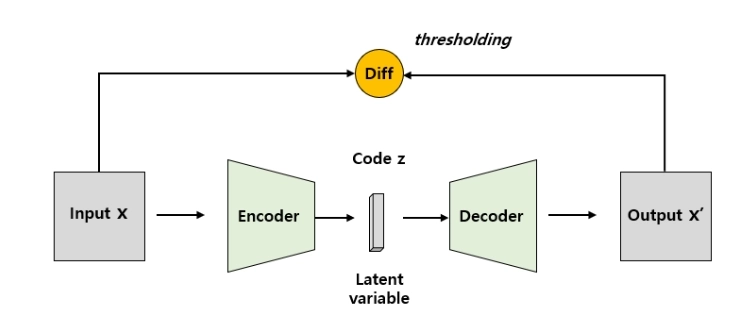
    - 선택: 간단한 방법(IQR, Z-score)부터 → 계절성 뚜렷하면 STL → 크고 복잡하면 모델 기반

- **이상치 처리**
    - 먼저 오류인지 실제 사건인지 확인
    - 삭제 (NaN으로 바꾼 뒤 다시 채움) 
    - 단순 대치 
    - **보간** (가장 많이 씀)

#### 2-2. 평활화

- **평활화**
: 자잘한 노이즈를 줄여 큰 흐름을 드러내는 기술 → 주로 EDA에서 사용

- **이동평균**
: N개씩 묶어 평균 내고 한 칸씩 이동
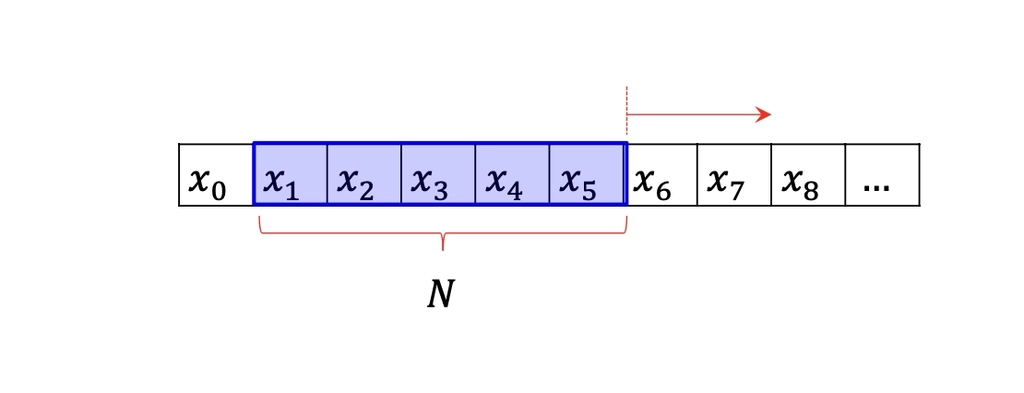
    - 예: 100, 130, 110, 140, 120 → (N=3) 113, 127, 123
    - N 작음: 변화에 빠르게 반응, 노이즈 남음 
    - N 큼: 매끄러움, 변화에 늦게 반응
    - 보고 싶은 흐름의 길이에 맞춰 N 결정
    - 용도: 노이즈 제거, 추세 파악, 계절성 제거, 결측치와 이상치 대치, ARIMA 기초 자료
    - 유형: SMA (모든 값 같은 가중치), WMA (최근 값에 더 큰 가중치), EMA (가중치가 지수적으로 감소)

#### 2-3. 요소분해

- **요소분해**
: 섞여 있는 시계열을 요인별로 나누는 과정
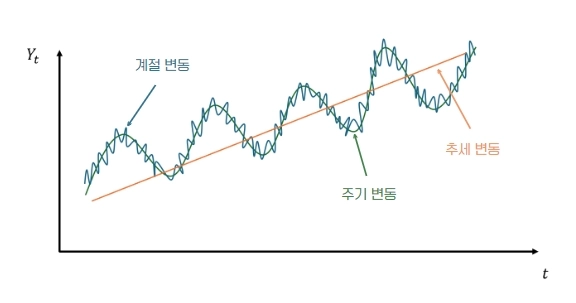
    - 순환은 따로 찾기 어려워 추세에 포함 → 보통 **T, S, R** 세 가지로 분해
    - 이유: 패턴 이해, 변동 원인 분석, 이상치 탐지, 계절조정, 예측 정확도 향상

- **분해 모형** (결합 방식)
    - 가법: $Y = T + S + R$ → 각 요인들이 독립적, 모든 요소 영향 일정
    - 승법: $Y = T × S × R$ → 추세와 계절성, 불규칙성 효과 비례
    - 그래프 물결 높이 일정 → 가법 / 점점 커짐 → 승법 (현실의 매출, 주가는 승법인 경우 많음)
    - 승법에 로그 취하면 가법처럼 다룰 수 있음

- **분해 방법** (계산 알고리즘)
    - **Seasonal Decompose**: 이동평균 기반, 단순
        - 중심 이동평균으로 T 추정 → Y에서 T 제거 → 같은 계절 위치끼리 평균해 S 도출 → 나머지가 R
    - **STL**: LOESS 기반, 유연하고 강건
        - LOESS: 각 지점마다 주변 데이터로 작은 회귀선 그림 → 이어붙여 곡선 만드는 방법 (가까울수록 가중치 ↑)
        - Inner Loop: T와 S를 번갈아 추정하며 다듬음
        - Outer Loop: 잔차 큰 시점(이상치)에 작은 가중치 → 이상치 영향 줄임 (robust)

---

### 3. 정상성

#### 3-1. 개념

- **정상성 (Stationarity)**
: 시간이 지나도 평균, 분산, 자기상관이 그대로 유지되는 성질 → 어느 시점에서 잘라 봐도 비슷한 모습
    - 정상: 일정한 선을 기준으로 오르내림, 벗어나도 돌아옴 (주가 등락률)
    - 비정상: 추세, 계절성, 분산 변화 (주가 자체, GDP, 항공 승객 수)
    - 중요한 이유: 과거 패턴 = 미래 패턴 가정이 성립하기 위한 조건 → 비정상이면 변환 후 분석

#### 3-2. 강한 / 약한 정상성

- **강한 정상성**: 확률분포 전체가 시간을 옮겨도 동일 
    - 왜도, 첨도까지 동일
    - 현실에선 거의 불가능
- **약한 정상성**: 아래 3가지만 만족 → AR, MA, ARIMA가 가정하는 정상성
    - 평균 일정
    - 분산 일정 (유한)
    - 자기공분산이 시점이 아닌 시차(h)에만 의존 
    - 대부분의 시계열 모델 = 약한 정상성

#### 3-3. 정상성 판단

- **시각적 판단**
    - 정상: 수평선 중심으로 비슷한 폭으로 오르내림, 평균 회귀, 반복 패턴 X
    - 비정상: 계속 오르내림 (추세), 주기 반복 (계절성), 폭이 커짐 (나팔 모양, 분산 변화)
    - ACF 그래프로도 확인 가능

- **단위근**
: 한 번 생긴 충격이 줄어들지 않고 누적되는 성질 → 비정상의 원인
    - $Y_t = φY_{t-1} + ε_t$
    - φ = 0.5: 충격이 점점 줄어 평균으로 돌아옴 → 정상
    - φ = 1 (단위근): 충격이 그대로 남고 계속 쌓임 → 평균 회귀 X, 분산 계속 증가 → 비정상

- **단위근 검정** → 두 검정은 귀무가설이 반대
    - ADF: 단위근 있음(비정상)이 기본 가정 → p < 0.05면 정상
    - KPSS: 정상이 기본 가정 → p < 0.05면 비정상
    - 기본 가정이 반대라서 둘을 같이 봐야 판단이 확실해짐
    - 둘 다 정상 → 그대로 모델링
    - 둘 다 비정상 → 정상성 확보 후 다시 검정
    - ADF만 비정상 → 추세만 빼면 정상 (추세 정상)
    - KPSS만 비정상 → 차분하면 정상 (차분 정상)

#### 3-4. 정상성 확보

- 비정상 원인별로 처방이 다름

- **추세 → 차분**
: 값 대신 바로 전 시점과의 차이 사용
    - 추세 제거 + 단위근 제거 (쌓이던 충격이 풀리고 새로 생긴 충격만 남음)
    - 종류: 1차 차분, 2차 차분 (차분을 한 번 더), 역차분 (예측 후 원래 값으로 되돌리기)
    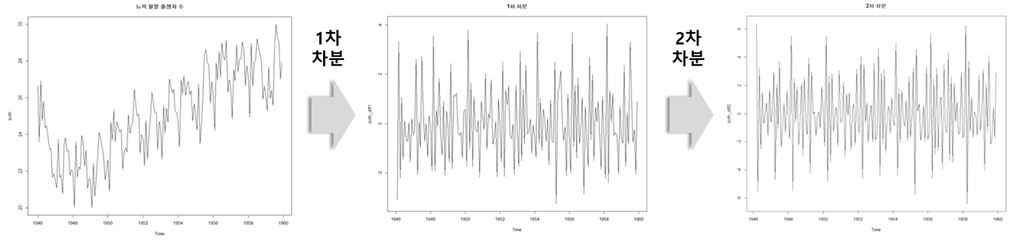

- **계절성 → 계절 차분**
: 오늘 값 − 한 주기(m) 전 값 사용 

- **분산 변화 → 로그 변환** 
    - 큰 값일수록 더 많이 줄어서 → 변동 폭 일정 (10, 100, 1000 → 1, 2, 3)
    - 곱하기 → 더하기 (승법 → 가법)
    - 한계: 0 이하 값엔 사용 불가 (0 있으면 +1 후 로그), 변동 폭이 값에 비례할 때만 효과적

- 흐름: 정상성 판단 → 비정상 유형별 정상성 확보 → 모델링

---

### 4. 단변량 시계열 분석

- 변수 하나의 과거만 보고 그 변수의 미래를 예측

#### 4-1. 안정적 시계열 분석

- 정상 시계열 → 결국 돌아온다고 가정

- **AR (자기회귀)**
: 과거의 '값'으로 현재를 설명
    - AR(1): $y_t = c + φ_1 y_{t-1} + ε_t$ → 오늘 = 어제 값의 일부 + 오늘 충격
    - AR(p): 과거 p개 시점의 값 사용

- **MA (이동평균)**
: 과거의 '충격'으로 현재를 설명
    - MA(1): $y_t = μ + ε_t + θ_1 ε_{t-1}$ → 오늘 = 오늘 충격 + 어제 충격의 일부
    - MA(q): 과거 q개 시점의 충격 사용

- 아직 모르는 오늘의 충격은 예측할 때 0으로 놓음

- **전제 조건**
    - 정상성: 충격 후 평소로 돌아올 수 있는가
        - AR은 계수 확인 필요 (AR(1)이면 계수 절댓값 < 1), MA는 항상 만족
    - 가역성: 관측된 값으로 과거 충격을 계산할 수 있는가
        - MA는 계수 확인 필요 (MA(1)이면 계수 절댓값 < 1), AR은 항상 만족
        - 계산이 불안정하면 오차가 계속 커져 예측이 무너짐
    - 단위근 검정은 데이터를 보는 것 → 서로 다름

- **ARMA(p, q)**
: AR + MA → 과거 값과 과거 충격을 함께 반영
    - AR만 쓰는 것보다 적은 계수로 설명 가능
    - ARMA(p,0) = AR(p), ARMA(0,q) = MA(q), ARMA(0,0) = 백색잡음

- **차수 결정: ACF / PACF**
    - ACF: 현재와 k시점 전의 상관 → q 결정
    - PACF: 사이 시점 영향을 빼고 본 직접 상관 → p 결정
    - 그래프 점선 안쪽 막대는 0
    - PACF가 p에서 끊기고 ACF는 천천히 감소 → AR(p)
    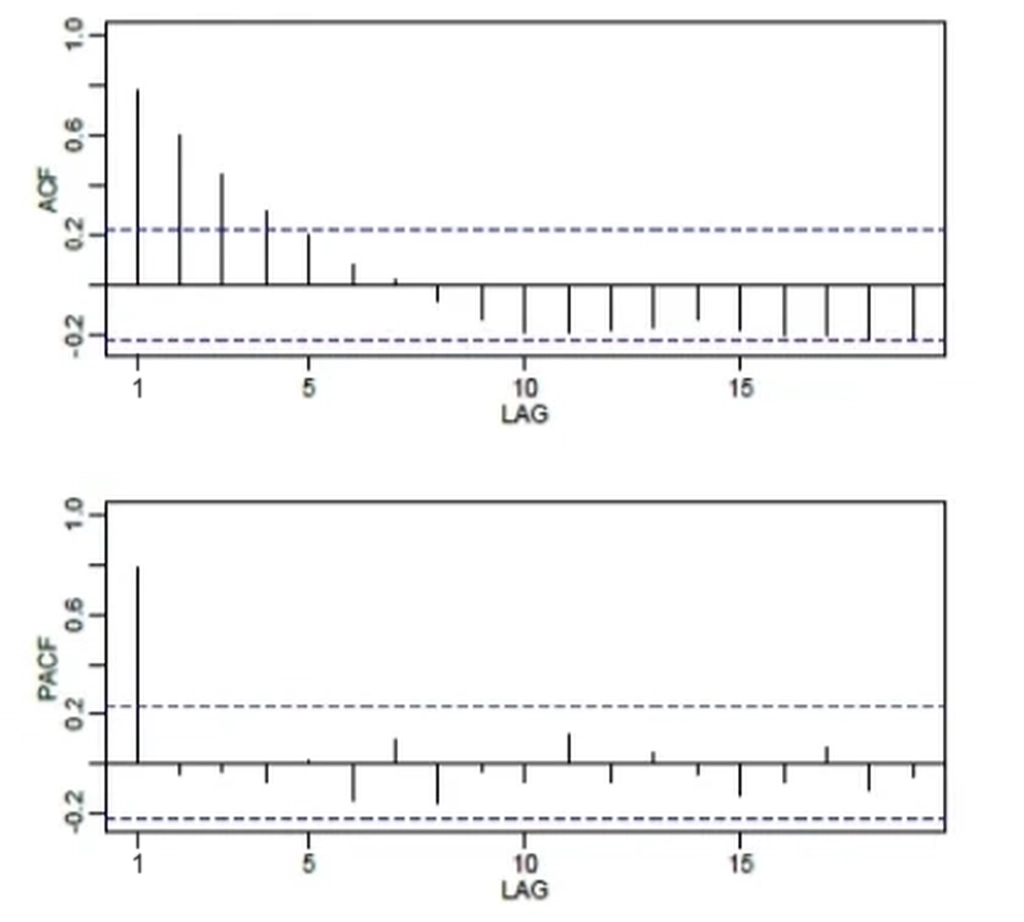
    - ACF가 q에서 끊기고 PACF는 천천히 감소 → MA(q)
    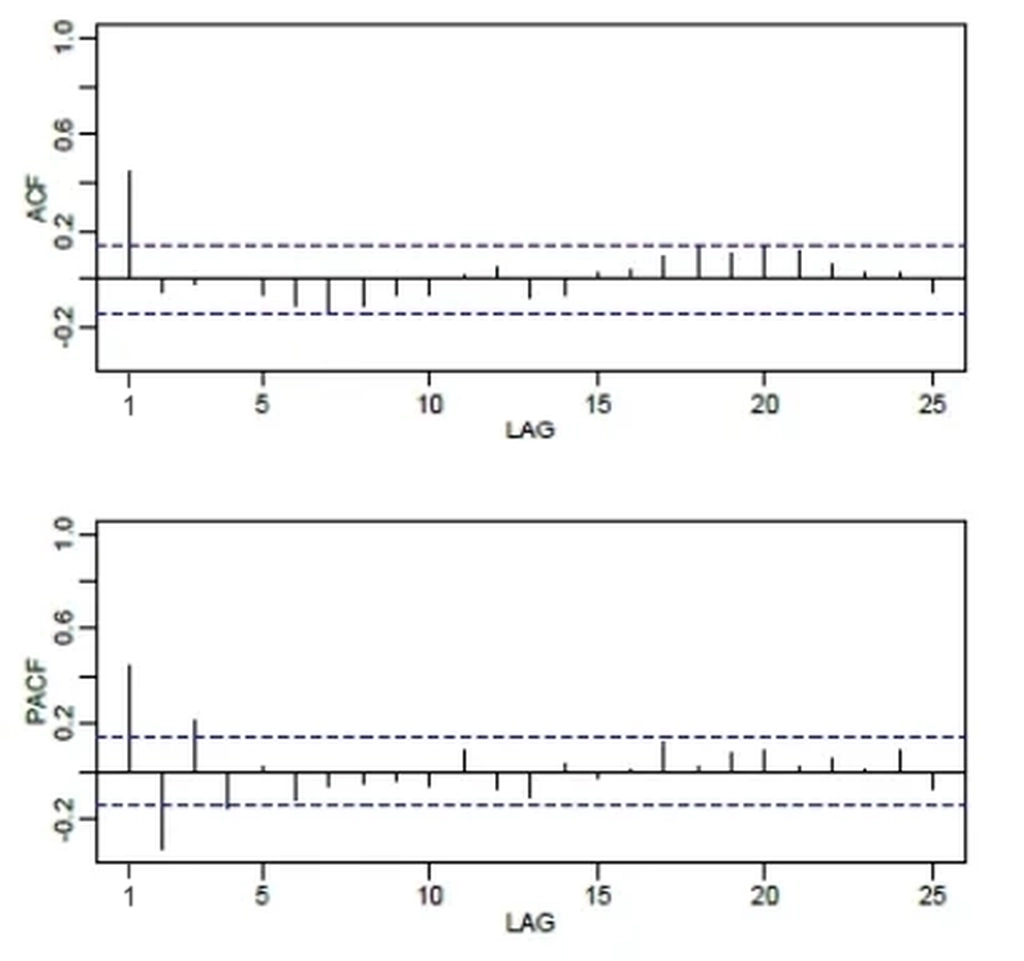
    - 둘 다 끊기면 → ARMA(p, q)
    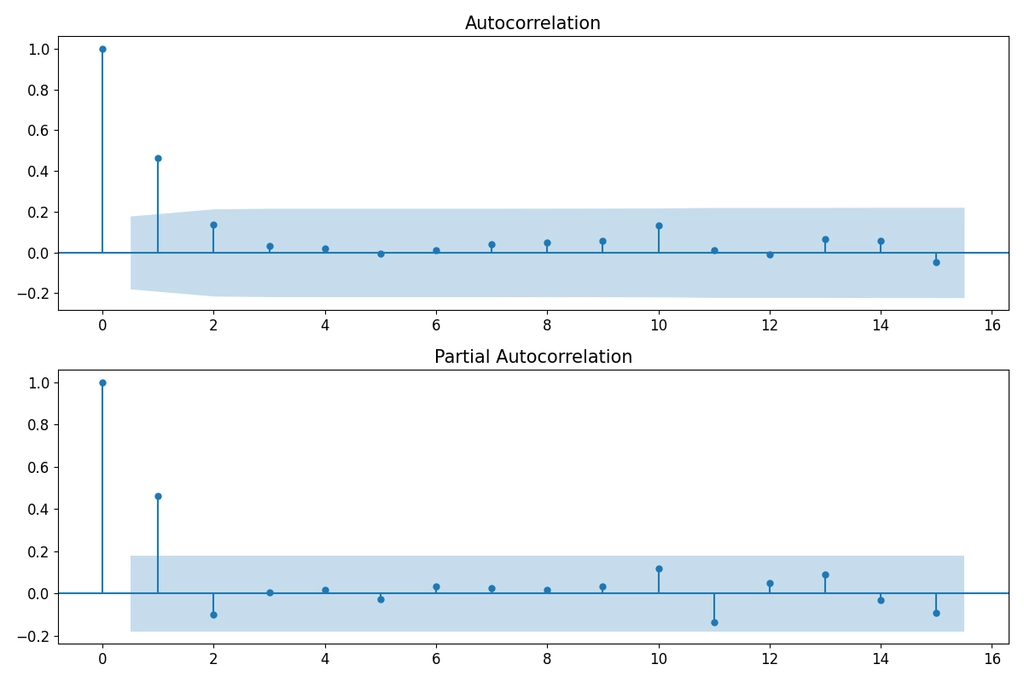

#### 4-2. 불안정 시계열 분석

- 추세나 계절성 때문에 기준선 없는 시계열 → 정상성 X
- 모형을 바꾸는 게 아니라 데이터를 정상으로 바꿔서 넣는 것
- ARMA + 차분, 계절성 차분

- **ARIMA(p, d, q)**
: ARMA + 차분 (p: AR 차수, d: 차분 횟수, q: MA 차수)
    - 차분해서 증감으로 → 증감을 ARMA로 예측 → 어제 값에 더해 되돌림
    - (0,0,0) 백색잡음, (p,0,0) AR, (0,0,q) MA, (0,1,0) 랜덤워크 (상수 있으면 표류 포함 → 방향성 생김)
    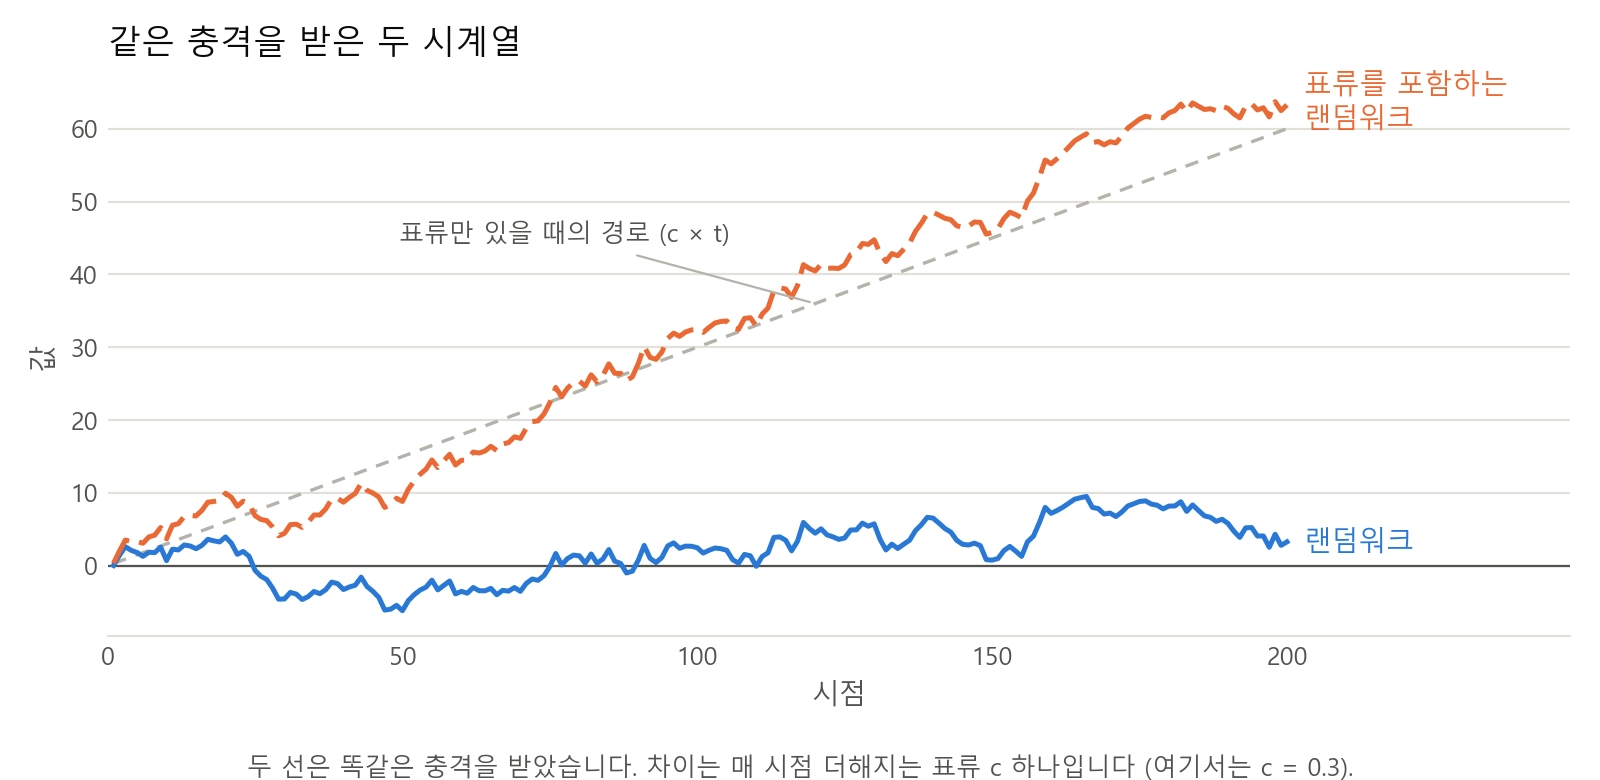

- **SARIMA(p, d, q)(P, D, Q)m**
: ARIMA + 계절 차분 + 계절 AR + 계절 MA
    - 지난달 대비 증감 → 추세 제거 / 작년 같은 달 대비 증감 → 계절 수준 제거
    - P, D, Q: p, d, q를 한 주기 전 기준으로 한 번 더 
    - m: 계절 주기 (월별 12, 분기 4, 요일 7)
    - 계절성 있으면 ACF가 주기마다 튐 → 계절 차분 먼저
    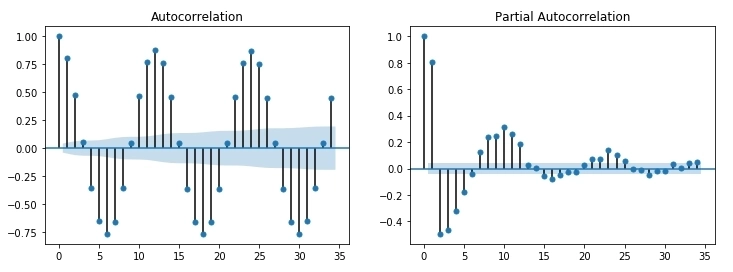

- **하이퍼파라미터 결정**
    - ACF, PACF는 시각적 도구일 뿐 → 명확하지 않을 때가 많음
    - d, D: 차분 후 단위근 검정으로 정상이 됐는지 확인 
    - p, q: 후보 조합을 AIC, BIC로 비교 (auto_arima 등)

---

### 5. 다변량 시계열 분석

- 여러 변수를 함께 보고, 각 변수를 자기 과거 + 다른 변수 과거로 예측

#### 5-1. VAR

- **VAR (Vector Autoregression)**
: AR을 여러 변수로 확장 → 변수마다 식 하나, 각 식에 모든 변수의 어제 값이 들어감
    - $a_{11}, a_{22}$: 자기 자신에게서 오는 영향 
    - $a_{12}, a_{21}$: 서로 주는 영향 (새로 생긴 계수)

- 적합: 양방향 영향, 한 변수의 변화가 다른 변수로 어떻게 퍼지는지 궁금할 때, 정상 (or 차분 후 정상), 변수 적고 데이터 충분
- 부적합: 한 방향 영향, 변수 많고 데이터 적음, 비선형 관계 → 딥러닝

- **분석 도구**
    - 충격 반응 함수 (IRF): 한 변수에 충격 → 다른 변수가 시간에 따라 어떻게 따라 움직이는지
    - 예측오차 분산 분해: 예측이 빗나간 정도를 어느 변수의 충격에서 얼마나 왔는지 비율로 확인

---

### 6. 딥러닝 시계열 분석

- 배경: 통계 모델 한계 → 데이터 많으면 느림, 고정 크기만 가능, 비선형 포착 어려움

- **RNN 계열** → 순차 패턴이 중요할 때 / 매우 긴 시계열, 병렬 처리엔 약함
    - RNN: 간단, 빠름 / 장기 의존성 X → 먼 과거는 기억 못 함
    - LSTM: 장기 의존성 O → 먼 과거까지 기억 / 복잡, 느림 
    - GRU: LSTM보다 빠름 / 장기 의존성 약함 

- **Transformer 계열**
    - Informer: 연산 줄여 긴 시계열 처리 / 짧은 시계열엔 과적합
    - Autoformer: 요소분해 개념 결합 → 주기 뚜렷한 판매량에 강함 / 구조 복잡
    - TFT: 외부 변수 함께 사용 + 어텐션으로 해석 가능 → 설명이 필요한 수요 예측에 많이 쓰임 / 학습 오래 걸림

- **Foundation Model**
: 거대 데이터로 미리 학습해 둔 범용 모델 → Fine-tuning으로 맞춤
    - LLM 기반: Without Adaptation (프롬프트), Adapt LLM (시계열로 Fine-tuning), Adapt to LLM (시계열 → 텍스트 변환)
    - 시계열 전용 모델: TimeGPT, TimesFM, Moirai, Chronos

- **선택 가이드**
    - 트레이드오프: 단순함 vs 성능 (RNN < LSTM/GRU < Transformer), 해석 vs 정확도, 학습 시간 vs 성능
    - 짧음 (< 100): 통계 모델, RNN
    - 중간 (100~1000): LSTM, GRU
    - 매우 김 (1000+): Informer, Autoformer
    - 주기 뚜렷: Autoformer / 외생 변수 많음: TFT / 범용: Foundation Model